# 13. Правила использования остаточных форматов METAR

Все 1102 остаточных сообщения после cloud-v2 получают явное решение об
использовании. Это завершение правил обработки, а не утверждение, что все
исходные тексты удалось полностью расшифровать. Поврежденные, неоднозначные
и неподдержанные группы остаются сохраненными без догадок и исправления.

Если проверен основной префикс, допускается его наблюдаемая погода; хвост
после QNH не используется для реконструкции признаков. Если основной блок
не проверен, его модельные погодные поля остаются неизвестными. Посадка
сохраняется. Предположение о задержке, числовые маски и пропуски действуют
дополнительно к этому правилу.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


decision_category,model_action,messages,old_baseline_rows
cloud_format_unresolved,model_weather_unknown,4,19
contradictory_cavok,model_weather_unknown,1,5
other_unverified_core,model_weather_unknown,58,242
pressure_group_unresolved,model_weather_unknown,26,111
validated_core_unparsed_tail,use_validated_core_only,698,2614
weather_meaning_unresolved,model_weather_unknown,180,413
wind_visibility_structure_unresolved,model_weather_unknown,135,517


decode_issues,model_action,messages
cavok_with_explicit_weather_or_cloud,model_weather_unknown,1
parser_error,model_weather_unknown,58
parser_error,use_validated_core_only,531
parser_error;qnh_group_missing_or_multiple,model_weather_unknown,5
parser_error;visibility_format_outside_pilot_scope,model_weather_unknown,43
parser_error;visibility_format_outside_pilot_scope;qnh_group_missing_or_multiple,model_weather_unknown,3
parser_error;wind_group_missing_or_multiple;visibility_format_outside_pilot_scope,model_weather_unknown,14
parser_error;wind_group_missing_or_multiple;visibility_format_outside_pilot_scope;qnh_group_missing_or_multiple,model_weather_unknown,1
parser_value_disagreement_cloud_layers,model_weather_unknown,4
parser_value_disagreement_weather,model_weather_unknown,180


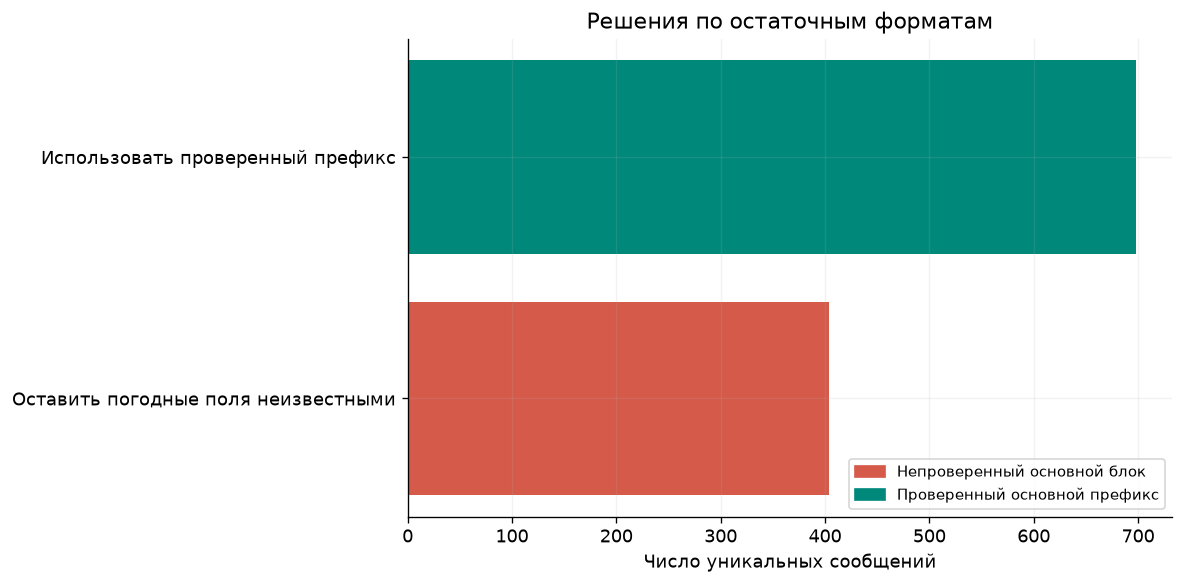

### cloud_format_unresolved

station,metar_utc,metar,decode_issues,core_validated,model_action
EIDW,2022-09-11 07:00:00+00:00,EIDW 110700Z 12005KT 100V170 9999 SCT0600 BKN100 15/13 Q1015 NOSIG,parser_value_disagreement_cloud_layers,False,model_weather_unknown
EIDW,2022-09-11 07:30:00+00:00,EIDW 110730Z 12005KT 100V170 9999 SCT0600 BKN100 15/13 Q1015 NOSIG,parser_value_disagreement_cloud_layers,False,model_weather_unknown
ESSA,2020-04-02 17:20:00+00:00,ESSA 021720Z 25018KT 8000 -SHRASN BKN017CB OVC3700 01/M01 Q0976 R01L/29//95 R01R/29//95 R08/29//95 TEMPO 4000 SHRASN BKN020CB,parser_value_disagreement_cloud_layers,False,model_weather_unknown
LIMC,2019-10-24 05:50:00+00:00,LIMC 240550Z 05003KT 360V080 3500 RA BR BKN015 OVC05 Q1016,parser_value_disagreement_cloud_layers,False,model_weather_unknown


### contradictory_cavok

station,metar_utc,metar,decode_issues,core_validated,model_action
ESSA,2019-06-21 05:20:00+00:00,ESSA 210520Z 24013KT CAVOK SCT020 16/12 Q1008 NOSIG,cavok_with_explicit_weather_or_cloud,False,model_weather_unknown


### other_unverified_core

...

station,metar_utc,metar,decode_issues,core_validated,model_action
EDDB,2021-01-25 03:20:00+00:00,EDDB 250320Z 28007KT 7000 BKN007 00/M01 Q0999 R88/D TEMPO 4500 BR BKN004,parser_error,True,use_validated_core_only
EDDB,2021-01-25 03:50:00+00:00,EDDB 250350Z 27005KT 9000 BKN008 00/M01 Q0999 R88/D TEMPO 4500 BR BKN004,parser_error,True,use_validated_core_only
EDDB,2021-01-25 04:20:00+00:00,COR EDDB 250420Z 26005KT 9999 BKN011 00/M00 Q0999 R88/D BECMG BKN015,parser_error,True,use_validated_core_only
EDDB,2021-01-25 04:50:00+00:00,EDDB 250450Z 27003KT 9999 FEW015 BKN028 M00/M01 Q1000 R88/D NOSIG,parser_error,True,use_validated_core_only
EDDB,2022-07-19 08:20:00+00:00,EDDB 190820Z AUTO 36004KT 280V070 9999 ///////// 29/09 Q1020 RE// BECMG CAVOK,parser_error,True,use_validated_core_only


### weather_meaning_unresolved

station,metar_utc,metar,decode_issues,core_validated,model_action
EDDM,2020-05-23 02:20:00+00:00,EDDM 230220Z 27004KT 9999 - SCT042 17/12 Q1022 NOSIG,parser_value_disagreement_weather,False,model_weather_unknown
EDDM,2021-05-06 03:20:00+00:00,EDDM 060320Z VRB01KT 9999 - FEW020 03/01 Q1012 NOSIG,parser_value_disagreement_weather,False,model_weather_unknown
EDDM,2021-12-02 23:20:00+00:00,EDDM 022320Z 29008KT 9000 - BKN010 BKN024 01/M01 Q1008 TEMPO SCT010 BKN020,parser_value_disagreement_weather,False,model_weather_unknown
EHAM,2019-04-03 13:55:00+00:00,EHAM 031355Z 12007KT 100V170 9999 - FEW015 SCT022CB BKN042 09/05 Q1000 NOSIG,parser_value_disagreement_weather,False,model_weather_unknown
EIDW,2020-10-05 16:00:00+00:00,EIDW 051600Z 27012KT 9999 - FEW014 SCT020 BKN100 12/09 Q0996 TEMPO BKN010,parser_value_disagreement_weather,False,model_weather_unknown


### wind_visibility_structure_unresolved

station,metar_utc,metar,decode_issues,core_validated,model_action
EDDM,2020-05-16 09:50:00+00:00,EDDM 160950Z 04005KT 010/V090 9999 FEW036 13/06 Q1022 NOSIG,parser_error;visibility_format_outside_pilot_scope,False,model_weather_unknown
EDDM,2020-05-16 10:20:00+00:00,EDDM 161020Z 07006KT 030/V120 9999 FEW036 14/04 Q1022 NOSIG,parser_error;visibility_format_outside_pilot_scope,False,model_weather_unknown
EDDM,2021-03-15 13:20:00+00:00,COR EDDM 151320Z 27014KT -RA FEW009 BKN012 04/02 Q1009 TEMPO BKN008,visibility_format_outside_pilot_scope,False,model_weather_unknown
EGLL,2020-12-27 22:20:00+00:00,COR EGLL 272220Z AUTO 16003KT 9999NOSIG FEW042 02/00 Q0972 NOSIG,parser_error;visibility_format_outside_pilot_scope,False,model_weather_unknown
EGLL,2021-02-16 18:50:00+00:00,COR EGLL 161850Z AUTO 2201NOSIG2KT 9999 FEW035 09/07 Q1008 NOSIG,parser_error;wind_group_missing_or_multiple;visibility_format_outside_pilot_scope,False,model_weather_unknown


In [2]:
cases=pd.read_csv(R/'22_residual_decision_register.csv',keep_default_na=False)
groups=pd.read_csv(R/'22_residual_decision_groups.csv')
assert cases.metar_id.is_unique and len(cases)==groups.messages.sum()==1102
assert cases.source_action.eq('preserve_without_repair').all()
assert cases.loc[cases.core_validated,'model_action'].eq('use_validated_core_only').all()
assert cases.loc[~cases.core_validated,'model_action'].eq('model_weather_unknown').all()
readable_table(groups)
readable_table(cases.groupby(['decode_issues','model_action']).size().rename('messages').reset_index())
fig,ax=plt.subplots(figsize=(10,5))
count=cases.groupby('model_action').size()
labels={'use_validated_core_only':'Использовать проверенный префикс',
    'model_weather_unknown':'Оставить погодные поля неизвестными'}
ax.barh([labels[x] for x in count.index],count.values,color=[CORAL,GREEN])
ax.set(xlabel='Число уникальных сообщений',title='Решения по остаточным форматам')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CORAL,label='Непроверенный основной блок'),
    Patch(color=GREEN,label='Проверенный основной префикс')],fontsize=9)
save('33_residual_decisions')
for category in groups.decision_category:
    display(Markdown('### '+category))
    readable_table(cases.loc[cases.decision_category.eq(category)].sort_values(['station','metar_utc']).head(5)[
        ['station','metar_utc','metar','decode_issues','core_validated','model_action']])


Нераспознанные погодные сочетания вроде FZBCFG/BCFZFG не преобразуются
в новые составные признаки без отдельной семантической проверки. Группы ВПП,
RE// и нетипичные обозначения тренда не исправляются автоматически. При
непроверенном префиксе консервативно блокируется весь модельный погодный блок;
это исследовательское ограничение использования, не доказательство ошибки
каждого числового поля. COR сохраняется как флаг исправленного сообщения.
[Протокол](../reports/22_final_weather_protocol.md).
